In [1]:
import numpy as np
import pandas as pd
import h5py
import os

import matplotlib.pyplot as plt
from matplotlib import cm
import plotly.graph_objects as go

sys.path.insert(0, "..")
from plot_style import *

from eazy import photoz
from eazy import hdf5 as eazyh5

import astropy.units as u
from astropy.coordinates import SkyCoord
from astropy.io import fits

from scipy import stats

NameError: name 'sys' is not defined

In [2]:
new = eazyh5.initialize_from_hdf5(h5file='/Users/jordan/Documents/Epochs/eazy/smiles/smiles_zphot.out.h5')
new_fsps_full = eazyh5.initialize_from_hdf5(h5file='/Users/jordan/Documents/Epochs/eazy/smiles_fsps_full/smiles_zphot_fsps_full.out.h5')
new_nircam = eazyh5.initialize_from_hdf5(h5file='/Users/jordan/Documents/Epochs/eazy/smiles_NIRCAM/smiles_zphot_NIRCAM.out.h5')

NameError: name 'eazyh5' is not defined

In [3]:
Ntemplates = np.sum(new.coeffs_best > 0, axis = 1)
Nfluxes = np.sum(new.efnu > -90, axis = 1)
pvalues = (1 - stats.chi2.cdf(new.chi2_best, df = new.nusefilt - Ntemplates - 1.0))
print( pvalues[11] )
print( new.chi2_best[11] )
print( new.zbest[11] )
print( new.nusefilt[11] )
print( Ntemplates[11] )

NameError: name 'new' is not defined

In [87]:
smiles_percentiles = new.pz_percentiles((0.5, 0.16, 0.84))

smiles_z50 = smiles_percentiles[:,0]
smiles_z16 = smiles_percentiles[:,1]
smiles_z84 = smiles_percentiles[:,2]

smiles_zlo = smiles_z50 - smiles_z16
smiles_zhi = smiles_z84 - smiles_z50

smiles_zbest = new.zml

smiles_nircam_percentiles = new_nircam.pz_percentiles((0.5, 0.16, 0.84))

smiles_nircam_z50 = smiles_nircam_percentiles[:,0]
smiles_nircam_z16 = smiles_nircam_percentiles[:,1]
smiles_nircam_z84 = smiles_nircam_percentiles[:,2]

smiles_nircam_zlo = smiles_nircam_z50 - smiles_nircam_z16
smiles_nircam_zhi = smiles_nircam_z84 - smiles_nircam_z50

smiles_nircam_zbest = new_nircam.zml


smiles_fsps_full_zbest = new_fsps_full.zml


In [104]:
np.where(smiles_fsps_full_zbest > 5)[0][10:50]

array([ 186,  213,  224,  226,  269,  300,  311,  363,  447,  499,  547,
        555,  562,  582,  608,  681,  684,  689,  703,  709,  739,  769,
        802,  822,  839,  863,  927,  942, 1026, 1039, 1042, 1051, 1078,
       1085, 1121, 1130, 1131, 1159, 1172, 1202])

In [80]:
## Load in the smiles nirspec catalogue
with fits.open("/Users/jordan/Documents/Epochs/data/spec/hlsp_smiles_jwst_nirspec_goodss_multi_v1.0_catalog.fits") as hdul:
    smiles_nirspec = hdul[1].data
    cols = hdul[1].columns
    # print(cols)

with fits.open("/Users/jordan/Documents/Epochs/data/spec/hlsp_jades_jwst_nirspec_goods-s_gratings-line-fluxes_v1.1_catalog.fits") as hdul:
    jades_nirspec = hdul[1].data
    cols = hdul[1].columns
    # print(cols)

In [81]:
smiles_prospect_cat_bc03_snorm = pd.read_csv("/Users/jordan/Documents/Epochs/prospect/photoZ_bc03_snorm_smiles_specz_astro_cat.csv")

In [182]:
## match JADES
catalogue = SkyCoord(ra=new.cat['ra']*u.degree, dec=new.cat['dec']*u.degree)
c = SkyCoord(ra=jades_nirspec.field('RA_TARG')*u.degree, dec=jades_nirspec.field('Dec_TARG')*u.degree)
idx, d2d, d3d = c.match_to_catalog_sky(catalogue)
sep_constraint = d2d < 0.3*u.arcsec

idx_jades_catalogue = idx[sep_constraint]
idx_jades = np.where(sep_constraint)[0]

zspec_flag_match = jades_nirspec['z_Spec_flag'][idx_jades]
idx_secure = np.where(np.isin(zspec_flag_match, ["A", "B", "C"]))

jades_zspec_match = jades_nirspec['z_Spec'][idx_jades][idx_secure]
jades_zphot_match = smiles_zbest[idx_jades_catalogue][idx_secure]
jades_zphot_nircam_match = smiles_nircam_zbest[idx_jades_catalogue][idx_secure]
jades_zphot_fsps_full_match = smiles_fsps_full_zbest[idx_jades_catalogue][idx_secure]

jades_match_chi2 = new.chi2_best[idx_jades_catalogue][idx_secure]
jades_nircam_match_chi2 = new_nircam.chi2_best[idx_jades_catalogue][idx_secure]

jades_Ntemplates = np.sum(new.coeffs_best > 0, axis = 1)[idx_jades_catalogue][idx_secure]
jades_Nfluxes = np.sum(new.efnu > -90, axis = 1)[idx_jades_catalogue][idx_secure]

jades_match_id = new.idx[idx_jades_catalogue][idx_secure]
## do Chi2 GOF test 
idx_bad_fit = (1 - stats.chi2.cdf(jades_match_chi2, df = jades_Nfluxes - jades_Ntemplates - 1.0)) < 0.05
idx_nircam_bad_fit = (1 - stats.chi2.cdf(jades_nircam_match_chi2, df = jades_Nfluxes - jades_Ntemplates - 1.0)) < 0.05

In [170]:
## match SMILES
catalogue = SkyCoord(ra=new.cat['ra']*u.degree, dec=new.cat['dec']*u.degree)
c = SkyCoord(ra=smiles_nirspec.field('RA')*u.degree, dec=smiles_nirspec.field('DEC')*u.degree)
idx, d2d, d3d = c.match_to_catalog_sky(catalogue)
sep_constraint = d2d < 0.3*u.arcsec

idx_smiles_catalogue = idx[sep_constraint]
idx_smiles = np.where(sep_constraint)[0]

zspec_flag_match = smiles_nirspec['Q'][idx_smiles]
idx_secure = np.where(np.isin(zspec_flag_match, ["A"]))

smiles_zspec_match = smiles_nirspec['z_Spec'][idx_smiles][idx_secure]
smiles_zphot_match = smiles_zbest[idx_smiles_catalogue][idx_secure]
smiles_z50_match = smiles_z50[idx_smiles_catalogue][idx_secure]
smiles_zlo_match = smiles_zlo[idx_smiles_catalogue][idx_secure]
smiles_zhi_match = smiles_zhi[idx_smiles_catalogue][idx_secure]
smiles_prospect_cat_bc03_snorm_match = smiles_prospect_cat_bc03_snorm.iloc[idx_secure]

In [ ]:
def compute_sigmaNMAD(zspec, zphot):
    deltaz = zphot - zspec
    sigmaNMAD = 1.48 * np.median( np.abs( (deltaz - np.median(deltaz)) / (1+zspec) ) )
    return sigmaNMAD

def compute_outliers(zspec, zphot):
    thresh = 0.15

    deltaz = abs(zphot - zspec)
    Noutlier = sum(deltaz > thresh * (1+zspec))
    print(Noutlier)
    print(len(zspec))
    outlier_frac = Noutlier / len(zspec)
    return outlier_frac

def compute_Nsigma_outliers(zspec, zphot, zphot_err, thresh = 2.0):

    deltaz = (abs(zphot - zspec))/zphot_err
    outlier_frac = sum(deltaz >= thresh) / len(zspec)
    
    return outlier_frac

45
346
15
89


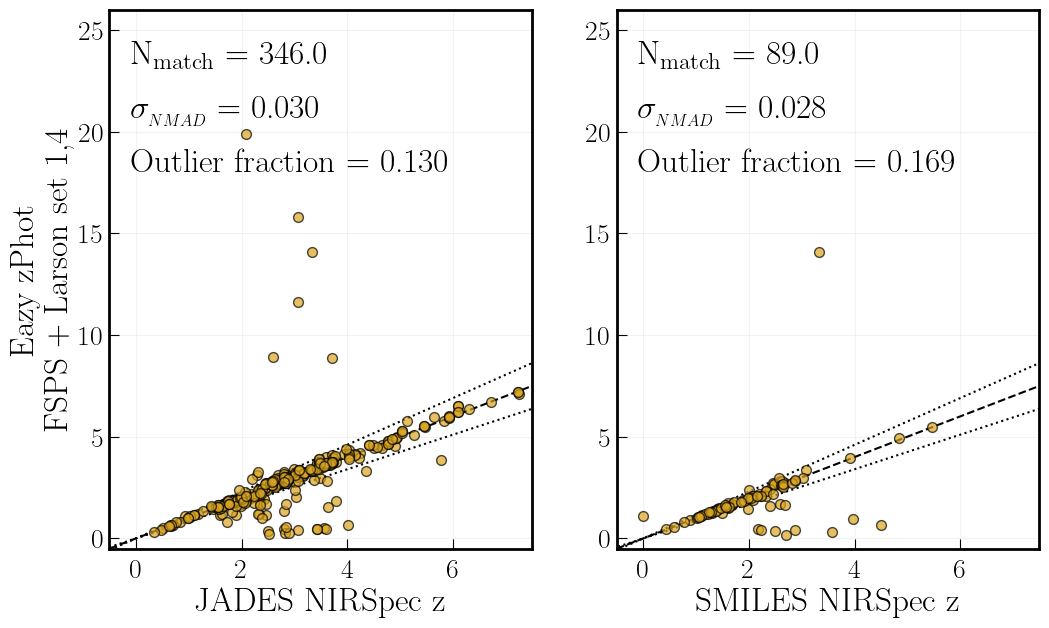

In [196]:
fig, axs = plt.subplots(1, 2, figsize = (12,7))

zbest_leg = axs[0].scatter(
    jades_zspec_match,
    jades_zphot_match, 
    s = 50, 
    zorder = 20, 
    edgecolor = "black",
    facecolor = "goldenrod",
    alpha = 0.7,
    label = "zbest"
)
zbest_leg = axs[1].scatter(
    smiles_zspec_match,
    smiles_zphot_match, 
    s = 50, 
    zorder = 20, 
    edgecolor = "black",
    facecolor = "goldenrod",
    alpha = 0.7,
    label = "zbest"
)

axs[0].text(
        0.05, 0.90, 
        rf"N$_{{\mathrm{{match}}}}$ =  {len(jades_zspec_match):.1f}", transform=axs[0].transAxes
    )
axs[0].text(
    0.05, 0.80, 
    rf"$\sigma_{{_{{NMAD}}}} = $ {compute_sigmaNMAD(zspec=jades_zspec_match, zphot=jades_zphot_match):.3f}", transform=axs[0].transAxes
)
axs[0].text(
    0.05, 0.70, 
    rf"Outlier fraction = {compute_outliers(zspec=jades_zspec_match, zphot=jades_zphot_match):.3f}", transform=axs[0].transAxes
)

axs[1].text(
        0.05, 0.90, 
        rf"N$_{{\mathrm{{match}}}}$ =  {len(smiles_zspec_match):.1f}", transform=axs[1].transAxes
    )
axs[1].text(
    0.05, 0.80, 
    rf"$\sigma_{{_{{NMAD}}}} = $ {compute_sigmaNMAD(zspec=smiles_zspec_match, zphot=smiles_zphot_match):.3f}", transform=axs[1].transAxes
)
axs[1].text(
    0.05, 0.70, 
    rf"Outlier fraction = {compute_outliers(zspec=smiles_zspec_match, zphot=smiles_zphot_match):.3f}", transform=axs[1].transAxes
)

for i, ax in enumerate(axs):
    
    ax.axline((0, 0), slope=1, 
                color='black', linestyle='--'
    )
    ax.set_xlim([-0.5, 7.5]),
    ax.set_ylim([-0.5, 26])
    ax.set_yticks([0, 5, 10, 15, 20, 25])


    ax.plot(np.linspace(-400, 400, 40) + 1, 1.15 * (np.linspace(-400, 400, 40) + 1), 
            color='black', linestyle=':'
    )
    ax.plot(np.linspace(-400, 400, 40) + 1, 0.85 * (np.linspace(-400, 400, 40) + 1), 
            color='black', linestyle=':'
    )

    ax.grid(color = 'grey', alpha = 0.1, ls = "-")

axs[0].set_xlabel('JADES NIRSpec z')
axs[1].set_xlabel('SMILES NIRSpec z')
axs[0].set_ylabel('Eazy zPhot \n FSPS + Larson set 1,4')

fig.align_labels() # Aligns the labels
# fig.tight_layout()


# fig.savefig("/Users/jordan/Documents/Epochs/plots/smiles_zspec_zphot.pdf", bbox_inches = 'tight')

33
322
45
346
43
333
50
346
54
346


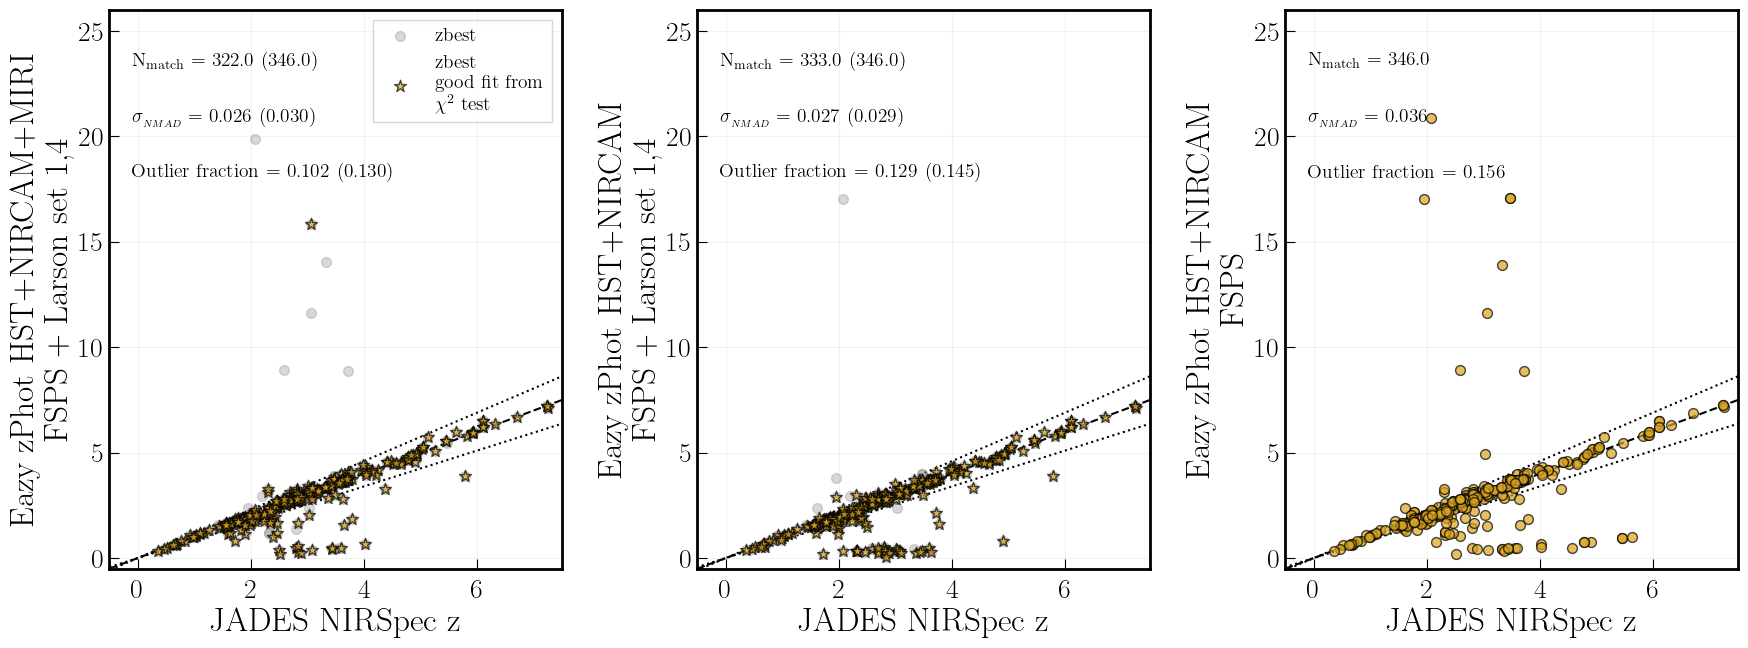

In [200]:
fig, axs = plt.subplots(1, 3, figsize = (18,7))

zbest_leg = axs[0].scatter(
    jades_zspec_match,
    jades_zphot_match, 
    s = 50, 
    zorder = 20, 
    edgecolor = "grey",
    facecolor = "grey",
    alpha = 0.3,
    label = "zbest"
)
zbest_leg = axs[0].scatter(
    jades_zspec_match[~idx_bad_fit],
    jades_zphot_match[~idx_bad_fit], 
    s = 80, 
    zorder = 20, 
    edgecolor = "black",
    facecolor = "goldenrod",
    marker = "*",
    alpha = 0.7,
    label = "zbest \n good fit from \n $\\chi^{2}$ test"
)
axs[1].scatter(
    jades_zspec_match,
    jades_zphot_nircam_match, 
    s = 50, 
    zorder = 20, 
    edgecolor = "grey",
    facecolor = "grey",
    alpha = 0.3,
    label = "zbest"
)
axs[1].scatter(
    jades_zspec_match[~idx_nircam_bad_fit],
    jades_zphot_nircam_match[~idx_nircam_bad_fit], 
    s = 80, 
    zorder = 20, 
    edgecolor = "black",
    facecolor = "goldenrod",
    marker = "*",
    alpha = 0.7,
    label = "zbest"
)
zbest_leg = axs[2].scatter(
    jades_zspec_match,
    jades_zphot_fsps_full_match, 
    s = 50, 
    zorder = 20, 
    edgecolor = "black",
    facecolor = "goldenrod",
    alpha = 0.7,
    label = "zbest"
)

axs[0].text(
        0.05, 0.90, 
        rf"N$_{{\mathrm{{match}}}}$ =  {len(jades_zspec_match[~idx_bad_fit]):.1f} ({len(jades_zspec_match):.1f})", transform=axs[0].transAxes,
        fontsize = 14
    )
axs[0].text(
    0.05, 0.80, 
    rf"$\sigma_{{_{{NMAD}}}} = $ {compute_sigmaNMAD(zspec=jades_zspec_match[~idx_bad_fit], zphot=jades_zphot_match[~idx_bad_fit]):.3f} ({compute_sigmaNMAD(zspec=jades_zspec_match, zphot=jades_zphot_match):.3f})", transform=axs[0].transAxes,
        fontsize = 14
)
axs[0].text(
    0.05, 0.70, 
    rf"Outlier fraction = {compute_outliers(zspec=jades_zspec_match[~idx_bad_fit], zphot=jades_zphot_match[~idx_bad_fit]):.3f} ({compute_outliers(zspec=jades_zspec_match, zphot=jades_zphot_match):.3f})", transform=axs[0].transAxes,
        fontsize = 14
)

axs[1].text(
        0.05, 0.90, 
        rf"N$_{{\mathrm{{match}}}}$ =  {len(jades_zspec_match[~idx_nircam_bad_fit]):.1f} ({len(jades_zspec_match):.1f})", transform=axs[1].transAxes,
        fontsize = 14
    )
axs[1].text(
    0.05, 0.80, 
    rf"$\sigma_{{_{{NMAD}}}} = $ {compute_sigmaNMAD(zspec=jades_zspec_match[~idx_nircam_bad_fit], zphot=jades_zphot_nircam_match[~idx_nircam_bad_fit]):.3f} ({compute_sigmaNMAD(zspec=jades_zspec_match, zphot=jades_zphot_nircam_match):.3f})", transform=axs[1].transAxes,
        fontsize = 14
)
axs[1].text(
    0.05, 0.70, 
    rf"Outlier fraction = {compute_outliers(zspec=jades_zspec_match[~idx_nircam_bad_fit], zphot=jades_zphot_nircam_match[~idx_nircam_bad_fit]):.3f} ({compute_outliers(zspec=jades_zspec_match, zphot=jades_zphot_nircam_match):.3f})", transform=axs[1].transAxes,
        fontsize = 14
)

axs[2].text(
        0.05, 0.90, 
        rf"N$_{{\mathrm{{match}}}}$ =  {len(jades_zspec_match):.1f}", transform=axs[2].transAxes,
        fontsize = 14
    )
axs[2].text(
    0.05, 0.80, 
    rf"$\sigma_{{_{{NMAD}}}} = $ {compute_sigmaNMAD(zspec=jades_zspec_match, zphot=jades_zphot_fsps_full_match):.3f}", transform=axs[2].transAxes,
        fontsize = 14
)
axs[2].text(
    0.05, 0.70, 
    rf"Outlier fraction = {compute_outliers(zspec=jades_zspec_match, zphot=jades_zphot_fsps_full_match):.3f}", transform=axs[2].transAxes,
        fontsize = 14
)

for i, ax in enumerate(axs):
    
    ax.axline((0, 0), slope=1, 
                color='black', linestyle='--'
    )
    ax.set_xlim([-0.5, 7.5]),
    ax.set_ylim([-0.5, 26])
    ax.set_yticks([0, 5, 10, 15, 20, 25])


    ax.plot(np.linspace(-400, 400, 40) + 1, 1.15 * (np.linspace(-400, 400, 40) + 1), 
            color='black', linestyle=':'
    )
    ax.plot(np.linspace(-400, 400, 40) + 1, 0.85 * (np.linspace(-400, 400, 40) + 1), 
            color='black', linestyle=':'
    )

    ax.grid(color = 'grey', alpha = 0.1, ls = "-")

axs[0].set_xlabel('JADES NIRSpec z')
axs[1].set_xlabel('JADES NIRSpec z')
axs[2].set_xlabel('JADES NIRSpec z')
axs[0].set_ylabel('Eazy zPhot HST+NIRCAM+MIRI \n FSPS + Larson set 1,4')
axs[1].set_ylabel('Eazy zPhot HST+NIRCAM \n FSPS + Larson set 1,4')
axs[2].set_ylabel('Eazy zPhot HST+NIRCAM \n FSPS')

axs[0].legend(fontsize = 14, fancybox = False)

# fig.align_labels() # Aligns the labels
fig.tight_layout()


fig.savefig("/Users/jordan/Documents/Epochs/plots/jades_zspec_smiles_zphot.pdf", bbox_inches = 'tight')

0.0014 +/- 0.0348, 0.0745
0.0011 +/- 0.0445, 0.0498
0.0008 +/- 0.0378, 0.0438


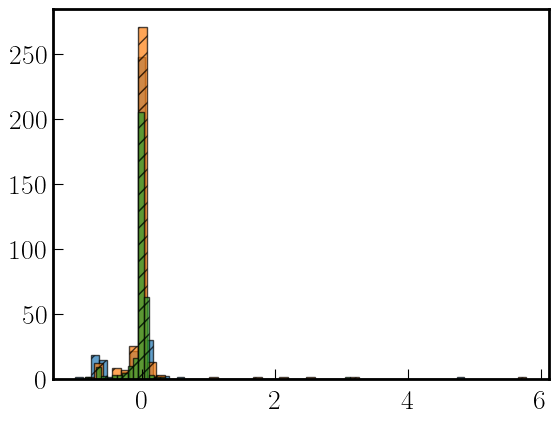

In [195]:
fig = plt.hist(
    (jades_zphot_nircam_match - jades_zspec_match) / (1+jades_zspec_match), bins = 50,
    edgecolor = "black", facecolor = "tab:blue", hatch = "//", alpha = 0.7
)
plt.hist(
    (jades_zphot_match - jades_zspec_match) / (1+jades_zspec_match), bins = 50,
    edgecolor = "black", facecolor = "tab:orange", hatch = "//", alpha = 0.7
)
plt.hist(
    (jades_zphot_match[~idx_bad_fit] - jades_zspec_match[~idx_bad_fit]) / (1+jades_zspec_match[~idx_bad_fit]), bins = 50,
    edgecolor = "black", facecolor = "tab:green", hatch = "//", alpha = 0.7
)

def print_deltaz_stats(zphot, zspec):
    med = np.quantile( (zphot - zspec) / (1+zspec) , (0.5))
    q16 = np.quantile( (zphot - zspec) / (1+zspec) , (0.16))
    q84 = np.quantile( (zphot - zspec) / (1+zspec) , (0.84))

    print(
        f"{med:.4f} +/- {q84-med:.4f}, {med-q16:.4f}"
    )

print_deltaz_stats(jades_zphot_nircam_match, jades_zspec_match)
print_deltaz_stats(jades_zphot_match, jades_zspec_match)
print_deltaz_stats(jades_zphot_match[~idx_bad_fit], jades_zspec_match[~idx_bad_fit])


[1240 2365   22 1131]
[2.82605    2.52180057 2.89054613]


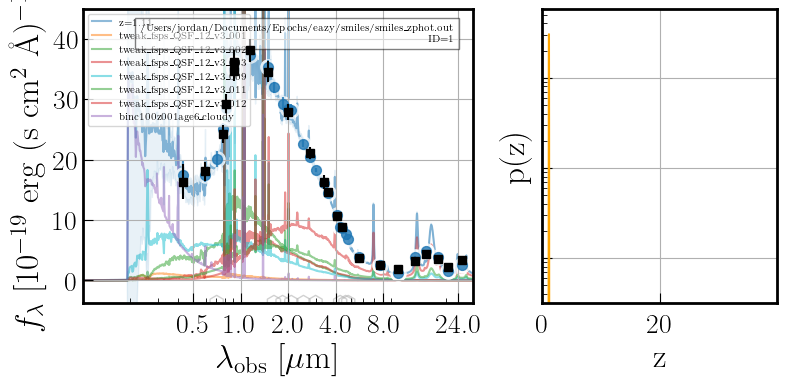

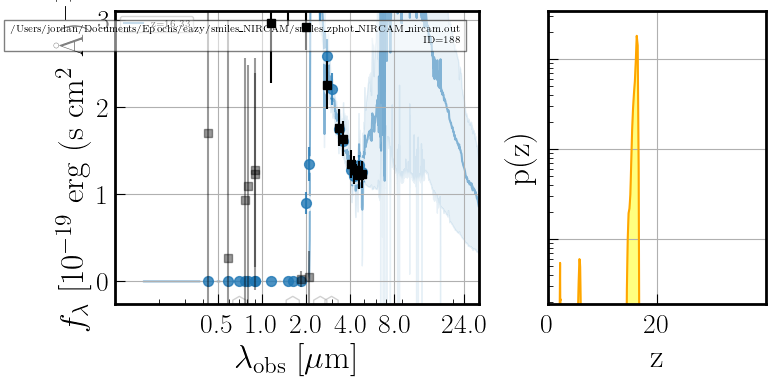

In [118]:
idx = jades_match_id[jades_zphot_match > 10.0]

print( idx )

print(jades_zspec_match[jades_zphot_match < 0.3])
fig = new.show_fit(0, id_is_idx=True, logpz=True, xlim = (0.1, 30), show_components=True)
fig2 = new_nircam.show_fit(187, id_is_idx=True, logpz=True, xlim = (0.1, 30))

In [108]:
new.zchi2[547]

np.float32(7.0845137)

In [12]:
# build your matrix
pz_matrix = np.zeros((len(zspec_match), len(new.zgrid)))
for i, result in enumerate(idx_catalogue):
    pz_matrix[i, :] = np.exp(new.lnp[result,:])   # or however you access per-galaxy Pz

0.0
nan
0.38149999999999995
0.578
0.7723
1.0960999999999999
1.3171
1.6225
2.084
2.6010999999999997
2.8775
3.6067
4.4986
5.3887
nan
7.2432


/var/folders/hv/hlgm1wrj0g7gzmpy8zr94wnw0000gn/T/ipykernel_1697/2963332999.py:17: RuntimeWarning: divide by zero encountered in log
  np.log(medianPz)
/Users/jordan/miniconda3/envs/eazy/lib/python3.14/site-packages/numpy/_core/fromnumeric.py:3824: RuntimeWarning: Mean of empty slice
  return _methods._mean(a, axis=axis, dtype=dtype,
/Users/jordan/miniconda3/envs/eazy/lib/python3.14/site-packages/numpy/_core/_methods.py:134: RuntimeWarning: invalid value encountered in divide
  ret = um.true_divide(
/Users/jordan/miniconda3/envs/eazy/lib/python3.14/site-packages/numpy/_core/_methods.py:142: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


Text(0.02, 0.5, 'Median $P(z)$')

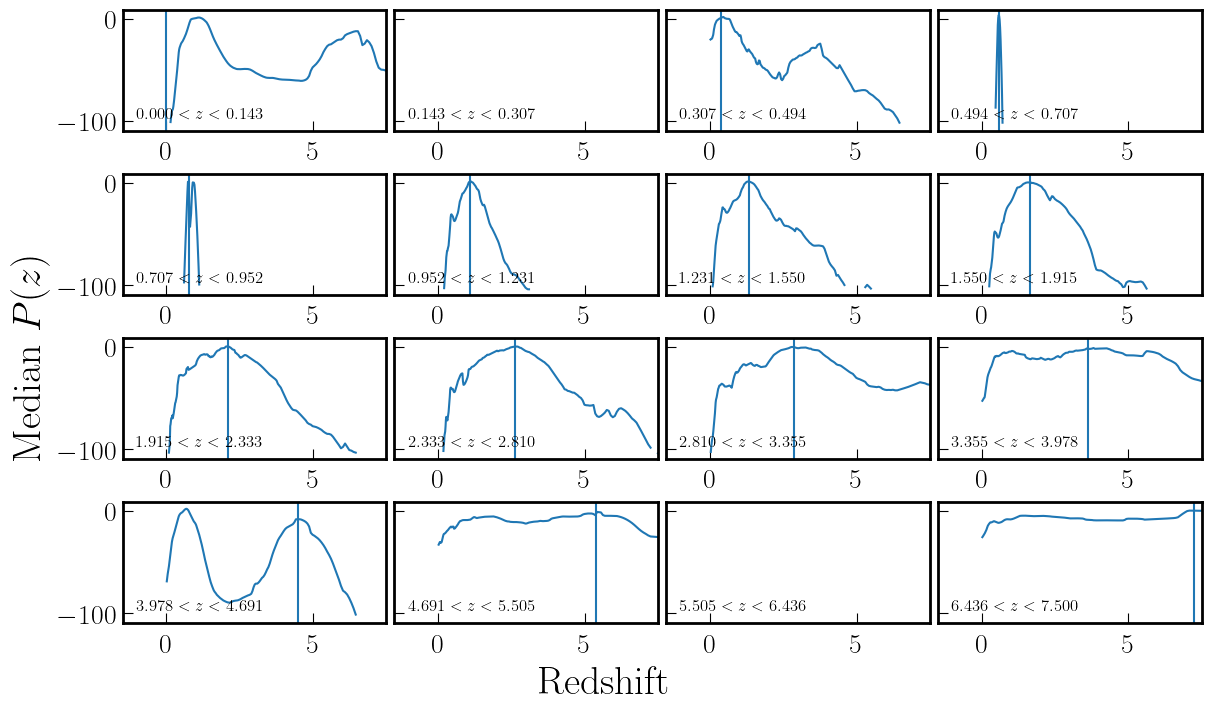

In [13]:
# zbins = np.array([0, 0.5, 1.0, 1.5, 2.0, 2.2, 2.5, 3.0, 4.0, 7.5])
# zbins = np.linspace(0, 7.3, 25)
# zbins = np.arange(0, 7.3, 0.1)
zbins = np.exp(np.linspace(np.log(1+0.0), np.log(1+7.5), 17))-1
zmids = zbins[0:-1] + 0.5*(zbins[1:] - zbins[:-1])

fig, ax = plt.subplots(4, 4, figsize = (12, 7), sharex=False, sharey=True, layout='constrained')

ax = ax.flatten()
for i, z in enumerate(zmids):
    zidx = np.where((zspec_match >= zbins[i]) & (zspec_match < zbins[i+1]))[0]

    medianPz = np.median(pz_matrix[zidx,:], axis = 0)

    ax[i].plot(
            new.zgrid,
            np.log(medianPz)
        )
    ax[i].axvline(
        np.median(zspec_match[zidx])
    )
    print(np.median(zspec_match[zidx]))
    ax[i].set_xlim([-1.5, 7.5])

    ax[i].text(
        0.05, 0.1, 
        f"{zbins[i]:.3f} $< z <$ {zbins[i+1]:.3f}", 
        transform = ax[i].transAxes, 
        fontsize = 12
    )
    # for j in zidx:
    #     ax[i].plot(
    #         np.log(1+new.zgrid),
    #         np.log(pz_matrix[j,:])
    #     )
    #     ax[i].axvline(
    #         np.log(1+zspec_match[j])
    #     )

fig.supxlabel("Redshift")
fig.supylabel("Median $P(z)$")

[  7  52  79 121]


/var/folders/hv/hlgm1wrj0g7gzmpy8zr94wnw0000gn/T/ipykernel_1697/1559832748.py:10: RuntimeWarning: divide by zero encountered in log
  np.log(pz_matrix[zidx[i]])/pz_matrix[zidx[i]].max(),


Text(0.02, 0.5, 'ln(P(z))')

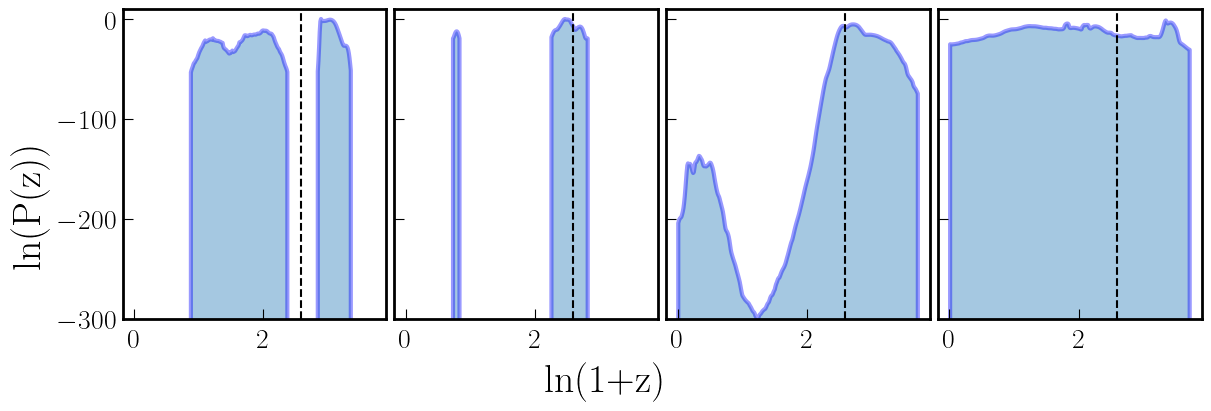

In [14]:
zidx = np.where(zphot_match >= 10)[0]
print(zidx)
fig, ax = plt.subplots(1, 4, figsize = (12, 4), sharex=True, sharey=True, layout = 'constrained')

for i in range(len(zidx)):
    ax[i].fill_between(
        np.log(1+new.zgrid), 
        -999,
        # pz_matrix[zidx[i]]/pz_matrix[zidx[i]].max(), 
        np.log(pz_matrix[zidx[i]])/pz_matrix[zidx[i]].max(), 
        alpha = 0.4, edgecolor = 'blue', lw = 3
    )
    ax[i].axvline(zspec_match[zidx[1]], color = "black", ls = "--")
    ax[i].set_ylim([-300, 10])
    # ax[i].set_yscale('log')

fig.supxlabel("ln(1+z)")
fig.supylabel("ln(P(z))")

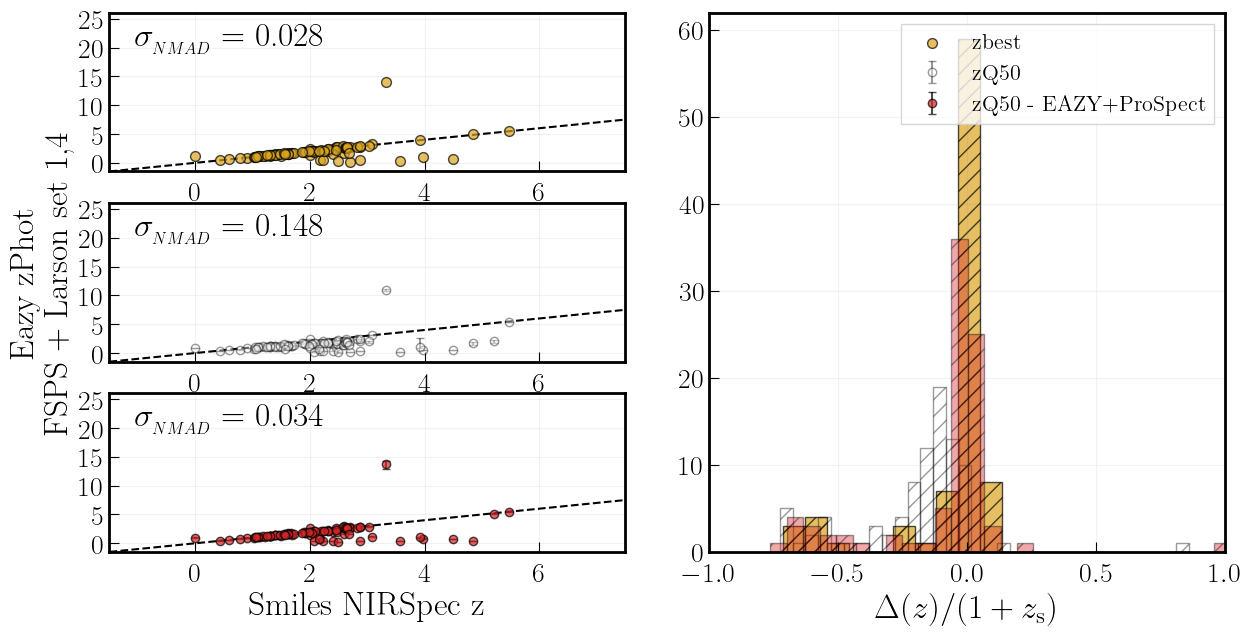

In [83]:
# fig, ax = plt.subplots(1, 2, figsize = (12,6))
# ax.scatter(
#     new.zbest[idx_catalogue],
#     smiles_nirspec.field('Z_SPEC')[idx_smiles]
# )
# plt.xlim([0,10]),
# plt.ylim([0,10])

fig = plt.figure(figsize = (12,7))
gs1 = GridSpec(3,3, left = 0.05, right = 0.48, wspace = 0.05)
ax1 = fig.add_subplot(gs1[0,:])
ax2 = fig.add_subplot(gs1[1,:], sharex = ax1, sharey = ax1)
ax3 = fig.add_subplot(gs1[2,:], sharex = ax1, sharey = ax1)

gs2 = GridSpec(3,3, left = 0.55, right = 0.98, wspace = 0.05)
ax4 = fig.add_subplot(gs2[:,:])

ax = [ax1,ax2,ax3,ax4]

zbest_leg = ax[0].scatter(
    smiles_zspec_match,
    smiles_zphot_match, 
    s = 50, 
    zorder = 20, 
    edgecolor = "black",
    facecolor = "goldenrod",
    alpha = 0.7,
    label = "zbest"
)
z50_leg = ax[1].errorbar(
    smiles_zspec_match,
    smiles_z50_match, 
    yerr = [smiles_zlo_match, smiles_zhi_match],
    fmt = "o",
    ls = "",
    markeredgecolor = "black",
    markerfacecolor = "white",
    ecolor = "black",
    alpha = 0.4,
    capsize = 3, 
    markersize = 6, 
    label = "zQ50"
)
zprospect_leg = ax[2].errorbar(
    smiles_zspec_match,
    smiles_prospect_cat_bc03_snorm_match["zQ50"], 
    yerr = [smiles_prospect_cat_bc03_snorm_match["z_lo"], smiles_prospect_cat_bc03_snorm_match["z_hi"]],
    fmt = "o",
    ls = "",
    markeredgecolor = "black",
    markerfacecolor = "tab:red",
    ecolor = "black",
    alpha = 0.7,
    capsize = 3, 
    markersize = 6, 
    label = "zQ50 - EAZY+ProSpect"
)
ax[0].text(
    0.05, 0.80, 
    rf"$\sigma_{{_{{NMAD}}}} = $ {compute_sigmaNMAD(zspec=smiles_zspec_match, zphot=smiles_zphot_match):.3f}", transform=ax[0].transAxes
)

ax[1].text(
    0.05, 0.80, 
    rf"$\sigma_{{_{{NMAD}}}} = $ {compute_sigmaNMAD(zspec=smiles_zspec_match, zphot=smiles_z50_match):.3f}", transform=ax[1].transAxes
)
ax[2].text(
    0.05, 0.80, 
    rf"$\sigma_{{_{{NMAD}}}} = $ {compute_sigmaNMAD(zspec=smiles_zspec_match, zphot=smiles_prospect_cat_bc03_snorm_match["zQ50"]):.3f}", transform=ax[2].transAxes
)

ax[0].axline((0, 0), slope=1, 
             color='black', linestyle='--'
)
ax[1].axline((0, 0), slope=1, 
             color='black', linestyle='--'
)
ax[2].axline((0, 0), slope=1, 
             color='black', linestyle='--'
)
ax[0].set_xlim([-1.5, 7.5]),
ax[0].set_ylim([-1.5, 26])
ax[0].set_yticks([0, 5, 10, 15, 20, 25])


# ax[0].plot(np.linspace(-400, 400, 40) + 1, 1.15 * (np.linspace(-400, 400, 40) + 1), 
#            color='black', linestyle=':'
# )
# ax[0].plot(np.linspace(-400, 400, 40) + 1, 0.85 * (np.linspace(-400, 400, 40) + 1), 
#            color='black', linestyle=':'
# )
ax[3].legend(handles = (zbest_leg, z50_leg, zprospect_leg), fontsize = 16, fancybox = False)
ax[2].set_xlabel('Smiles NIRSpec z')
ax[1].set_ylabel('Eazy zPhot \n FSPS + Larson set 1,4')

ax[3].hist(
    (smiles_zphot_match - smiles_zspec_match) / (1+smiles_zspec_match), bins = 50,
    edgecolor = "black", facecolor = "goldenrod", hatch = "//", alpha = 0.7
)
ax[3].hist(
    (smiles_z50_match - smiles_zspec_match) / (1+smiles_zspec_match), bins = 50,
    edgecolor = "black", facecolor = "none", hatch = "//", alpha = 0.4
)
ax[3].hist(
    (smiles_prospect_cat_bc03_snorm_match["zQ50"] - smiles_zspec_match) / (1+smiles_zspec_match), bins = 50,
    edgecolor = "black", facecolor = "tab:red", hatch = "//", alpha = 0.4
)

ax[3].set_xlim(-1, 1)
# ax[1].set_yscale('log')
ax[3].set_xlabel(r"$\Delta(z)/(1+z_{\mathrm{s}})$")

fig.align_labels() # Aligns the labels
# fig.tight_layout()

for ax in ax:
    ax.grid(color = 'grey', alpha = 0.1, ls = "-")
fig.savefig("/Users/jordan/Documents/Epochs/plots/smiles_zspec_zphot.pdf", bbox_inches = 'tight')

In [84]:
np.median( (smiles_prospect_cat_bc03_snorm_match["zQ50"] - smiles_zspec_match) / (1+smiles_zspec_match) )

np.float64(-0.00963648553700332)

Text(0.02, 0.5, '$\\frac{ z_{\\mathrm{phot}} - z_{\\mathrm{spec}} }{\\sigma_{z_{\\mathrm{phot}}}}$')

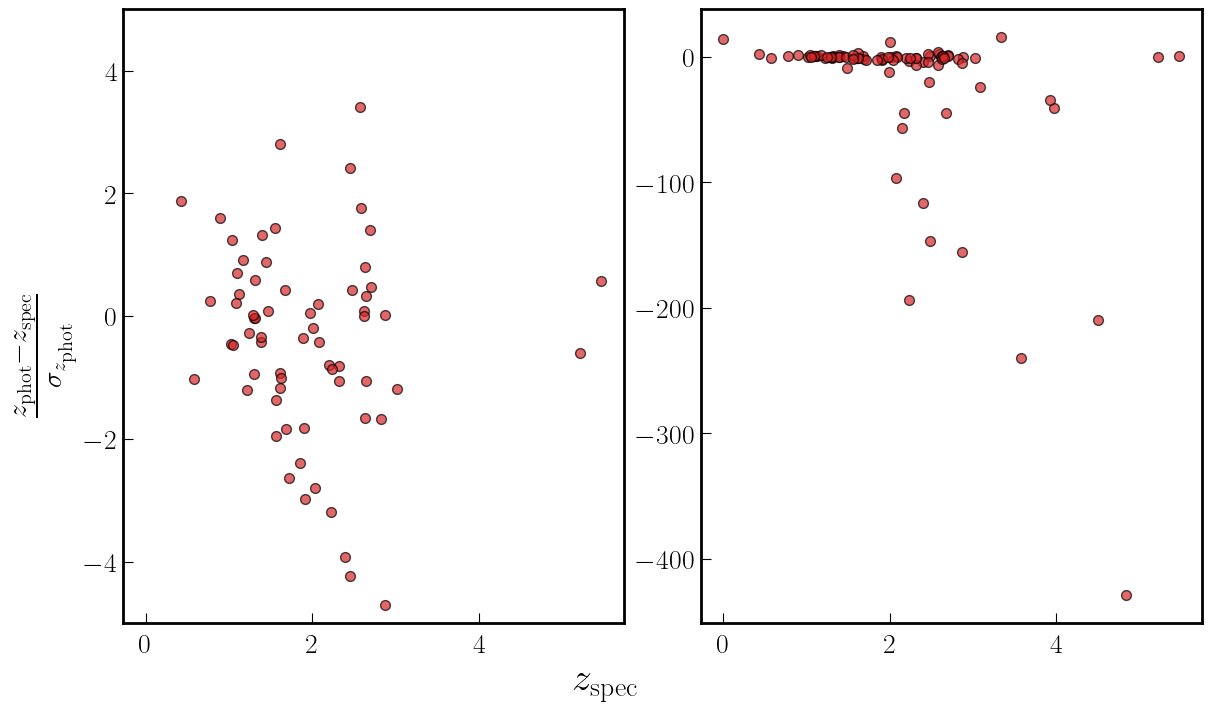

In [86]:
fig, ax = plt.subplots(1,2, layout = "constrained", figsize = (12, 7))
ax[0].scatter(
    smiles_zspec_match,
    (smiles_prospect_cat_bc03_snorm_match["zQ50"] - smiles_zspec_match) / (0.5*(smiles_prospect_cat_bc03_snorm_match["z_lo"] + smiles_prospect_cat_bc03_snorm_match["z_hi"])), 
    s = 50, 
    zorder = 20, 
    edgecolor = "black",
    facecolor = "tab:red",
    alpha = 0.7,
    label = "zbest"
)
ax[1].scatter(
    smiles_zspec_match,
    (smiles_prospect_cat_bc03_snorm_match["zQ50"] - smiles_zspec_match) / (0.5*(smiles_prospect_cat_bc03_snorm_match["z_lo"] + smiles_prospect_cat_bc03_snorm_match["z_hi"])), 
    s = 50, 
    zorder = 20, 
    edgecolor = "black",
    facecolor = "tab:red",
    alpha = 0.7,
    label = "zbest"
)

ax[0].set_ylim([-5.0,5.0])

fig.supxlabel(r"$z_{\mathrm{spec}}$")
fig.supylabel(r"$\frac{ z_{\mathrm{phot}} - z_{\mathrm{spec}} }{\sigma_{z_{\mathrm{phot}}}}$")


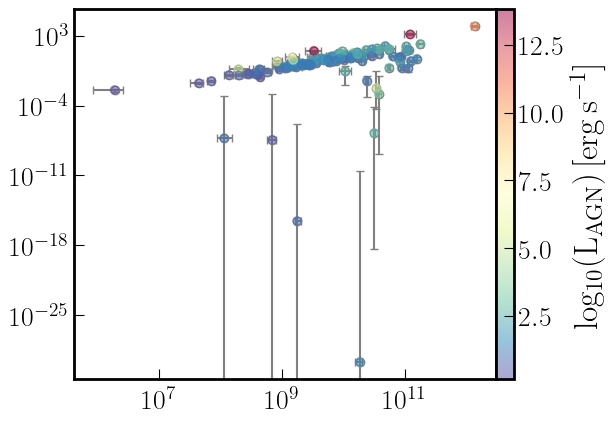

In [88]:
fig, ax = plt.subplots(1,1)

# ax.scatter(
#     smiles_prospect_cat["StellarMassQ50"],
#     smiles_prospect_cat["SFR10Q50"]
# )
sc_ = ax.scatter(
    smiles_prospect_cat_bc03_snorm["StellarMassQ50"],
    smiles_prospect_cat_bc03_snorm["SFR10Q50"],
    c = smiles_prospect_cat_bc03_snorm["zQ50"],
    zorder = 200,
    alpha = 0.5,
    cmap='Spectral_r'
)
ax.errorbar(
    smiles_prospect_cat_bc03_snorm["StellarMassQ50"],
    smiles_prospect_cat_bc03_snorm["SFR10Q50"],
    xerr = [smiles_prospect_cat_bc03_snorm["StellarMass_lo"], smiles_prospect_cat_bc03_snorm["StellarMass_hi"]],
    yerr = [smiles_prospect_cat_bc03_snorm["SFR10_lo"], smiles_prospect_cat_bc03_snorm["SFR10_hi"]],
    fmt = "o",
    markerfacecolor = "none", 
    markeredgecolor = "grey",
    ecolor = "grey",
    capsize = 3,
)
ax.set_xscale('log')
ax.set_yscale('log')

fig.colorbar(sc_, ax=ax, label=r'$\mathrm{log_{10}(L_{AGN}) \, [erg \, s^{-1}]}$', pad = 0.0)

In [18]:
cat = smiles_prospect_cat

log_agn  = np.log10(cat["AGNlumQ50"])
z_q50    = cat["zQ50"]

color_options = {
    "log₁₀(L_AGN) [erg s⁻¹]": log_agn,
    "zQ50":                     z_q50,
}

colorbar_titles = {
    "log₁₀(L_AGN) [erg s⁻¹]": "log₁₀(L<sub>AGN</sub>) [erg s⁻¹]",
    "zQ50":                     "z<sub>Q50</sub>",
}

fig = go.Figure()

# Error bars
fig.add_trace(go.Scatter(
    x=cat["StellarMassQ50"],
    y=cat["SFR10Q50"],
    mode="markers",
    marker=dict(
        color="rgba(0,0,0,0)",
        line=dict(color="grey", width=1),
        size=8,
    ),
    error_x=dict(
        type="data",
        symmetric=False,
        array=cat["StellarMass_hi"],
        arrayminus=cat["StellarMass_lo"],
        color="grey",
        thickness=1,
        width=3,
    ),
    error_y=dict(
        type="data",
        symmetric=False,
        array=cat["SFR10_hi"],
        arrayminus=cat["SFR10_lo"],
        color="grey",
        thickness=1,
        width=3,
    ),
    showlegend=False,
    hoverinfo="skip",
))

buttons = []
for label, cdata in color_options.items():
    buttons.append(dict(
        label=label,
        method="restyle",
        args=[{
            "marker.color": [cdata],
            "marker.colorbar.title.text": [colorbar_titles[label]],
        }, [1]],   # index 1 = scatter trace only
    ))

# Scatter coloured by log AGN lum
fig.add_trace(go.Scatter(
    x=cat["StellarMassQ50"],
    y=cat["SFR10Q50"],
    mode="markers",
    marker=dict(
        color=log_agn,
        colorscale="Spectral_r",
        opacity=0.7,
        size=8,
        colorbar=dict(
            title=dict(
                text="log₁₀(L<sub>AGN</sub>) [erg s⁻¹]",
                side="right",
            ),
            thickness=15,
        ),
        line=dict(color="black", width=0.3),
        showscale=True,
    ),
    customdata=np.stack([log_agn, z_q50, cat["StellarMassQ50"], cat["SFR10Q50"], zspec_match], axis=-1),
    hovertemplate=(
        "M★: %{customdata[2]:.2e} M☉<br>"
        "SFR: %{customdata[3]:.2e} M☉/yr<br>"
        "log L_AGN: %{customdata[0]:.2f}<br>"
        "zQ50: %{customdata[1]:.3f}<br>"
        "zspec: %{customdata[4]:.3f}<extra></extra>" 
    ),
    showlegend=False,
))

fig.update_layout(
    updatemenus=[dict(
        buttons=buttons,
        direction="down",
        x=0.0,
        xanchor="left",
        y=1.12,
        yanchor="top",
        showactive=True,
    )],
    xaxis=dict(
        title="Stellar Mass [M☉]",
        type="log",
        exponentformat="power",
        # tickformat='.0e',
        showgrid=True, gridcolor="lightgrey",
        minor=dict(showgrid=True, gridcolor="whitesmoke"),
    ),
    yaxis=dict(
        title="SFR₁₀ [M☉ yr⁻¹]",
        type="log",
        exponentformat="power",
        # tickformat='.0e',
        showgrid=True, gridcolor="lightgrey",
        minor=dict(showgrid=True, gridcolor="whitesmoke"),
    ),
    plot_bgcolor="white",
    width=1200, height=750,
    margin=dict(l=60, r=80, t=80, b=60),
)

fig.show()

# fig.write_html('/Users/jordan/Documents/Epochs/plots/smiles_SFR_Mstar.html')

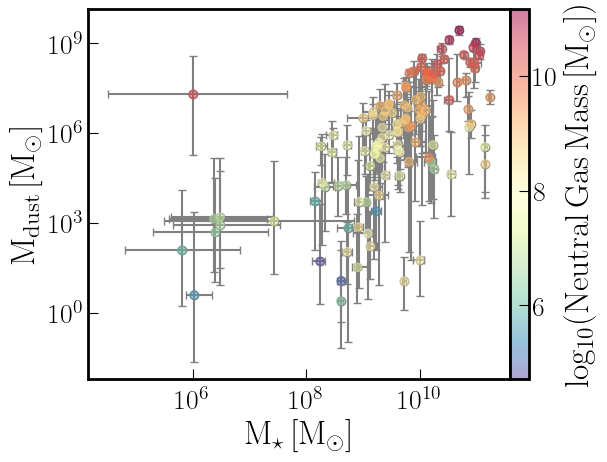

In [26]:
fig, ax = plt.subplots(1,1)

# ax.scatter(
#     smiles_prospect_cat["StellarMassQ50"],
#     smiles_prospect_cat["SFR10Q50"]
# )
sc_ = ax.scatter(
    smiles_prospect_cat["StellarMassQ50"],
    smiles_prospect_cat["DustMassTotalQ50"],
    c = np.log10(smiles_prospect_cat["NgasMassTotalQ50"]),
    zorder = 200,
    alpha = 0.5,
    cmap='Spectral_r'
)
ax.errorbar(
    smiles_prospect_cat["StellarMassQ50"],
    smiles_prospect_cat["DustMassTotalQ50"],
    xerr = [smiles_prospect_cat["StellarMass_lo"], smiles_prospect_cat["StellarMass_hi"]],
    yerr = [smiles_prospect_cat["DustMassTotal_lo"], smiles_prospect_cat["DustMassTotal_hi"]],
    fmt = "o",
    markerfacecolor = "none", 
    markeredgecolor = "grey",
    ecolor = "grey",
    capsize = 3,
)
ax.set_xscale('log')
ax.set_yscale('log')

ax.set_xlabel(r'$\mathrm{M_{\star} \, [M_{\odot}]}$')
ax.set_ylabel(r'$\mathrm{M_{dust} \, [M_{\odot}]}$')

fig.colorbar(sc_, ax=ax, label=r'$\mathrm{log_{10}(Neutral \, Gas \, Mass \, [M_{\odot}])}$', pad = 0.0)